In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from subprocess import run, PIPE
import sys
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from pathlib import Path

# ── 1. Load data ──────────────────────────────────────────────────────────────
icon = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/ICON_cycle4_summer_2020-2049_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']


# Land-sea mask (shared value dimension with icon)
land_sea_icon_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']


# Apply land mask and slice to 2020–2049 (indices 30–60)
icon_land = icon.where(land_sea_icon_zoom9 < 1, np.nan)#[31:60, :]

# ── 2. Split into first 15 and last 15 years ──────────────────────────────────


early = icon_land.isel(year=slice(1,15))
late = icon_land.isel(year=slice(15,30))

# ── 3. Define dry-spell bins and compute area fractions ───────────────────────
bin_edges  = [0, 10, 20, 30, 50, np.inf]
bin_labels = ['0–10', '10–20', '20–30', '30–50', '50+']

def area_fractions(da):
    """
    For a DataArray with dims (year, value), compute the mean area fraction (%)
    in each dry-spell bin, averaged across years.
    Land points only (NaNs already applied via land-sea mask).
    """
    fracs_per_year = []
    for yr in da.year.values:
        vals = da.sel(year=yr).values.ravel()
        vals = vals[~np.isnan(vals)]
        total = vals.size
        if total == 0:
            fracs_per_year.append([np.nan] * len(bin_labels))
            continue
        fracs = []
        for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
            mask = (vals >= lo) & (vals < hi)
            fracs.append(100.0 * mask.sum() / total)
        fracs_per_year.append(fracs)
    return np.array(fracs_per_year)   # shape: (n_years, n_bins)

early_fracs = area_fractions(early)   # (15, 5)
late_fracs  = area_fractions(late)    # (15, 5)

early_mean = np.nanmean(early_fracs, axis=0)
late_mean  = np.nanmean(late_fracs,  axis=0)

#pct_change = 100.0 * (late_mean - early_mean) / early_mean   # relative % change
pct_change = late_mean - early_mean



In [5]:
print(icon.year)

<xarray.DataArray 'year' (year: 30)> Size: 240B
array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])
Dimensions without coordinates: year


In [6]:
print(early)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 14, cell: 574808)> Size: 64MB
array([[ 59.,  93.,  43., ...,  13.,  14.,  13.],
       [ 79.,  81.,  80., ...,  29.,  29.,  29.],
       [ 88.,  52.,  70., ...,  18.,  22.,  34.],
       ...,
       [104., 105., 104., ...,  19.,  19.,  19.],
       [110., 112.,  72., ...,  23.,  35.,  31.],
       [136.,  89., 136., ...,  26.,  45.,  29.]])
Coordinates:
  * cell     (cell) int64 5MB 0 1 2 3 4 5 ... 574803 574804 574805 574806 574807
    lat      (cell) float64 5MB 30.09 30.09 30.09 30.17 ... 41.61 41.61 41.71
    lon      (cell) float64 5MB 56.07 55.72 55.9 55.99 ... 270.1 269.9 270.0
Dimensions without coordinates: year


In [7]:
print(late)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 15, cell: 574808)> Size: 69MB
array([[137.,  92.,  66., ...,  47.,  37.,  47.],
       [ 96., 103.,  75., ...,  60.,  60.,  70.],
       [ 81., 184.,  81., ...,  23.,  20.,  19.],
       ...,
       [179., 179.,  96., ...,  23.,  23.,  23.],
       [ 72., 111.,  59., ...,  29.,  29.,  29.],
       [ 99.,  99.,  99., ...,  20.,  34.,  18.]])
Coordinates:
  * cell     (cell) int64 5MB 0 1 2 3 4 5 ... 574803 574804 574805 574806 574807
    lat      (cell) float64 5MB 30.09 30.09 30.09 30.17 ... 41.61 41.61 41.71
    lon      (cell) float64 5MB 56.07 55.72 55.9 55.99 ... 270.1 269.9 270.0
Dimensions without coordinates: year


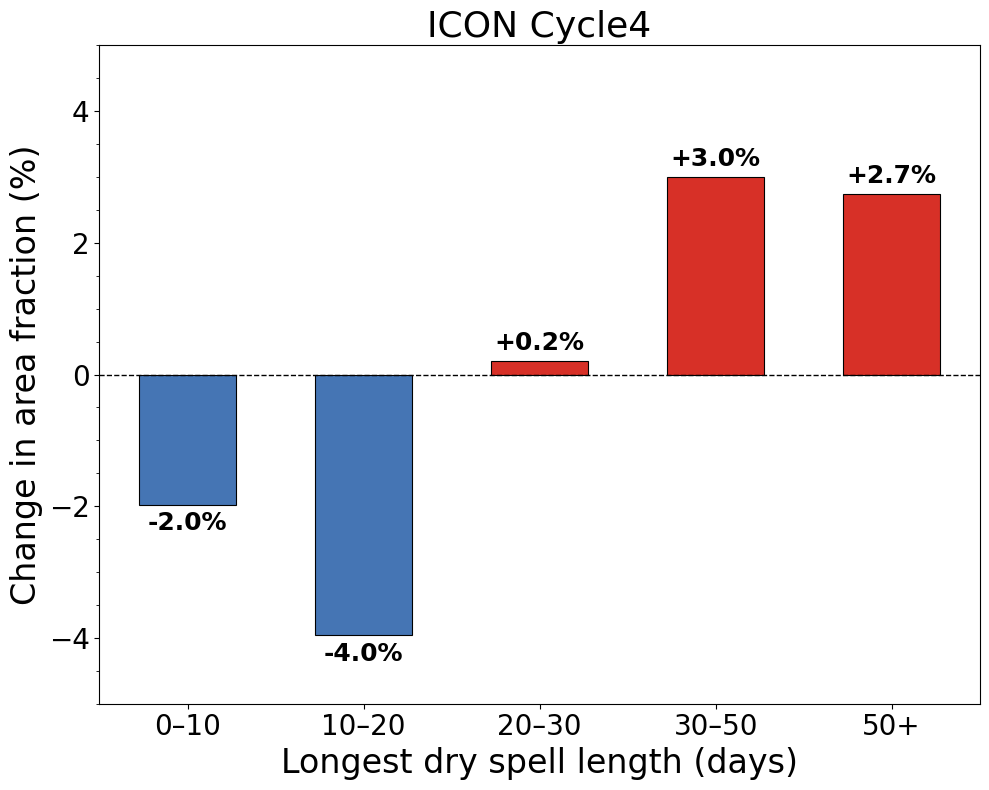

In [8]:
# ── 4. Plot ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))

x      = np.arange(len(bin_labels))
width  = 0.55
colors = ['#d73027' if v >= 0 else '#4575b4' for v in pct_change]

bars = ax.bar(x, pct_change, width=width, color=colors, edgecolor='k', linewidth=0.8)

# Annotate bars with numeric values
for bar, val in zip(bars, pct_change):
    yoffset = 0.1 if val >= 0 else -0.1
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + yoffset,
        f'{val:+.1f}%',
        ha='center',
        va='bottom' if val >= 0 else 'top',
        fontsize=18, fontweight='bold'
    )

ax.axhline(0, color='black', linewidth=1.0, linestyle='--')

ax.set_xticks(x)
ax.set_xticklabels(bin_labels, fontsize=20)
ax.set_xlabel('Longest dry spell length (days)', fontsize=24)
ax.set_ylabel('Change in area fraction (%)', fontsize=24)
ax.tick_params(axis='both', labelsize=20)
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax.set_ylim(-5, 5)
ax.set_title('ICON Cycle4',fontsize=26)

legend_elements = [
    Patch(facecolor='#d73027', edgecolor='k', label='Increase'),
    Patch(facecolor='#4575b4', edgecolor='k', label='Decrease'),
]
#ax.legend(handles=legend_elements, fontsize=14, loc='upper right')

plt.tight_layout()
plt.savefig(
    '/home/jwille/images/global_paper/mid_lat_land_ICON_cycle4_barplot_dry_spell_change.pdf',
    format='pdf', bbox_inches='tight')
plt.show()